Let's make the map. 

In [1]:
import sys
import os
from pathlib import Path

# Add project root to sys.path to access scripts
# Assuming notebook is running from notebooks/pipeline/
current_dir = Path(os.getcwd()).resolve()
if current_dir.name == 'pipeline':
    project_root = current_dir.parent.parent
else:
    # Fallback or assumed root
    project_root = current_dir

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import ProjectPaths
from scripts.paths import ProjectPaths

# Standard Libraries
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# Add any other libraries originally in this cell (e.g., imageio, glob)

In [2]:
# Analysis Parameters
TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2

In [3]:
# Load data using ProjectPaths and Geopandas
# using gpd.read_feather ensures it loads as a GeoDataFrame, enabling .geometry.x/y accessors
print(f"Loading data from: {ProjectPaths.MERGED_DATA_FILE}")
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Filter data using variables from parameters cell
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) & 
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID)
].copy()

print(f"Filtered data shape: {summer_bottom_df.shape}")
print(f"Data type: {type(summer_bottom_df)}") # Should say geopandas.geodataframe.GeoDataFrame
print(summer_bottom_df.head())

Loading data from: /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather
Filtered data shape: (5381, 65)
Data type: <class 'geopandas.geodataframe.GeoDataFrame'>
      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-0

First, let's make the base map to show all of the sampling points in the SIS area. We will be using ```merged_gdf``` as the data source. The map will be color-coded based on the different water-masses indicated by the ```'division'``` column.

In [4]:
unique_points = summer_bottom_df['zettaicode'].drop_duplicates().tolist() # or .unique() can also work
print(unique_points)
print(f"Number of unique sampling points: {len(unique_points)}")

['00002811', '00002823', '00000272', '00000275', '00002725', '00036147', '00044533', '00044575', '00044578', '00044527', '00033182', '00035565', '00033237', '00035562', '00033224', '00035588', '00033241', '00033248', '00033204', '00035598', '00033277', '00034285', '00034310', '00033276', '00034332', '00034344', '00038667', '00035582', '00038671', '00035613', '00035626', '00035707', '00040632', '00003695', '00003698', '00034312', '00036103', '00038674', '00036164', '00044594', '00044529', '00044677', '00003089', '00040714', '00040715', '00036110', '00028169', '00035550', '00044531', '00037170', '00003086', '00044605', '00002750', '00002758', '00037179', '00035521', '00035522', '00034391', '00037213', '00035484', '00037181', '00037195', '00034423', '00037263', '00035512', '00038469', '00037238', '00044690', '00037250', '00037254', '00037298', '00038274', '00038647', '00038665', '00002848', '00028119', '00035486', '00038441', '00038495', '00002737', '00002744', '00044679', '00044680', '00

/tmp/ipykernel_143211/1309042603.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors_map = plt.cm.get_cmap('jet', len(divisions))


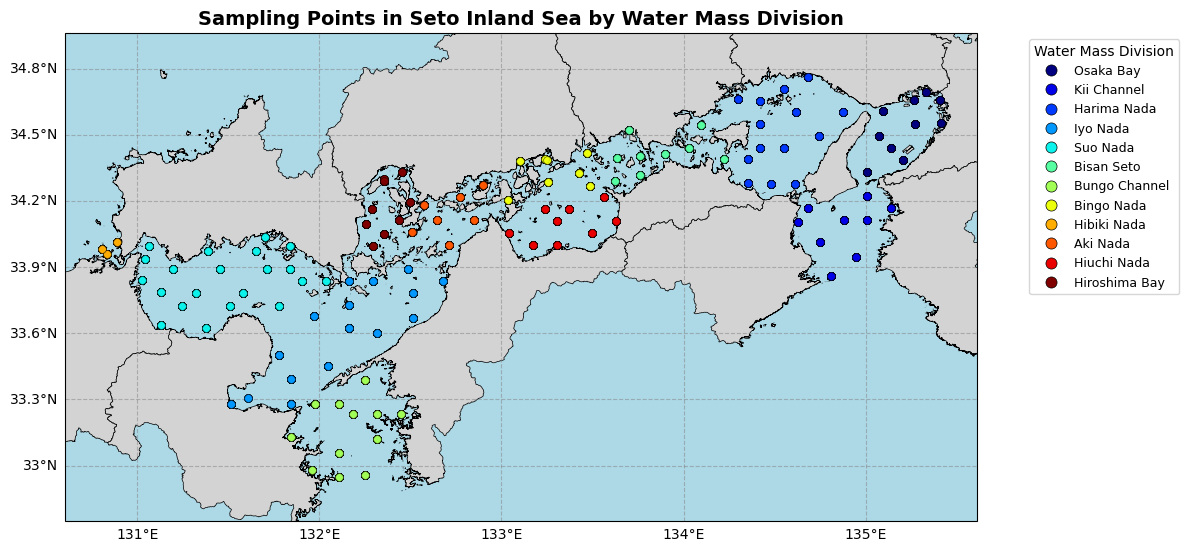

Total sampling points: 127
water masses: ['Osaka Bay', 'Kii Channel', 'Harima Nada', 'Iyo Nada', 'Suo Nada', 'Bisan Seto', 'Bungo Channel', 'Bingo Nada', 'Hibiki Nada', 'Aki Nada', 'Hiuchi Nada', 'Hiroshima Bay']


In [5]:
# Create base map with all sampling points colored by division (WITHOUT labels)
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Standard: Facecolor for Ocean
ax.set_facecolor('lightblue')

# Standard: Load SIS Boundary
boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_boundary = gpd.read_file(boundary_path)
if sis_boundary.crs != "EPSG:4326":
    sis_boundary = sis_boundary.to_crs("EPSG:4326")

# Standard: Plot Land with zorder=1
sis_boundary.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)

# Standard: Gridlines with zorder=2
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
gl.top_labels = False
gl.right_labels = False

# Get unique divisions and assign colors
divisions = merged_gdf['division'].unique()
colors_map = plt.cm.get_cmap('jet', len(divisions))
division_color_map = {div: colors_map(i) for i, div in enumerate(divisions)}

# Plot points colored by division with zorder=3
legend_elements = []
for division in divisions:
    div_data = merged_gdf[merged_gdf['division'] == division]
    ax.scatter(
        div_data.geometry.x, 
        div_data.geometry.y, 
        s=30,
        alpha=0.6,
        color=division_color_map[division],
        transform=ccrs.PlateCarree(),
        edgecolors='black',
        linewidth=0.3,
        zorder=3
    )
    from matplotlib.lines import Line2D
    legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                   markerfacecolor=division_color_map[division],
                                   markersize=8, markeredgecolor='black', 
                                   markeredgewidth=0.5, label=division))

ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05, 1), fontsize=9, title='Water Mass Division')
ax.set_title('Sampling Points in Seto Inland Sea by Water Mass Division', fontsize=14, fontweight='bold')

# Standard: Tightly buffered extent
bounds = merged_gdf.total_bounds
ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())

plt.tight_layout()
plt.show()

print(f"Total sampling points: {len(unique_points)}")
print(f"water masses: {list(divisions)}")

Nice. Now let's make the frequency occurence map.

Map saved to: /home/reyha/SIS_Analysis_WSL/figures/hypoxia_map_summer_point2.png


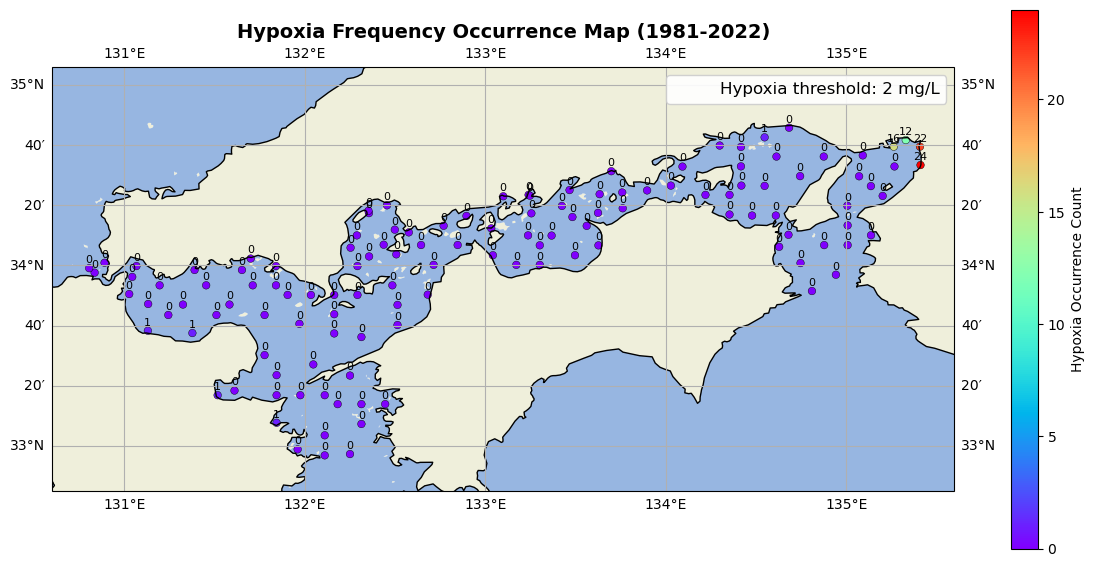

Total sampling points: 127
Max Occurrences: 24


In [9]:
# Define hypoxia threshold
hypoxia_threshold = 2
hypoxia_df = summer_bottom_df[summer_bottom_df['do_'] < hypoxia_threshold]

# Count occurrences for each unique 'zettaicode'
station_counts = hypoxia_df.groupby('zettaicode')['year'].nunique().reset_index(name='hypoxia_count')

# Merge with all stations to include those with 0 occurrences
all_stations = summer_bottom_df[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
plot_data = all_stations.merge(station_counts, on='zettaicode', how='left')
plot_data['hypoxia_count'] = plot_data['hypoxia_count'].fillna(0) # 0 occurrences for others

# === Plotting ===
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# Determine color scale components
# Blue to Red color scale
# Upper bound = ceil(max)
max_count = plot_data['hypoxia_count'].max()
vmax_val = np.ceil(max_count) if not pd.isna(max_count) and max_count > 0 else 5

# Plot points colored by hypoxia frequency
# Replaces the division loop with a single scatter plot mapped to the 'hypoxia_count' column
sc = ax.scatter(
    plot_data.geometry.x, 
    plot_data.geometry.y, 
    s=30,
    alpha=1,
    c=plot_data['hypoxia_count'],
    cmap='rainbow',
    vmin=0, 
    vmax=None,
    transform=ccrs.PlateCarree(),
    edgecolors='black',
    linewidth=0.3
)

# --- NEW: Add Count Labels above points ---
for idx, row in plot_data.iterrows():
    # Only label points that exist (though all should exist here)
    # Offset y by a small amount (e.g., 0.02 degrees) to place text above the dot
    x, y = row.geometry.x, row.geometry.y
    count = int(row['hypoxia_count'])
    
    ax.text(x, y + 0.02, str(count),
            fontsize=8, 
            ha='center', 
            va='bottom', 
            fontweight='normal',
            color='black',
            transform=ccrs.PlateCarree())

# --- NEW: Add Legend for Threshold ---
# Create an invisible plot element just to hold the label in the legend
ax.plot([], [], ' ', label=f"Hypoxia threshold: {hypoxia_threshold} mg/L")
ax.legend(loc='upper right', framealpha=0.9, fontsize=12)

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.05)
cbar.set_label('Hypoxia Occurrence Count')
ax.set_title('Hypoxia Frequency Occurrence Map (1981-2022)', fontsize=14, fontweight='bold')

plt.tight_layout()

# Example: Save the current figure
# Ensure you call this before plt.show() if reusing the figure object, 
# or ensure the figure object is active.

output_filename = f"hypoxia_map_{TARGET_SEASON.lower()}_point{SAISUIPOIN_ID}.png"
output_path = ProjectPaths.FIGURES_DIR / output_filename

# Save figure
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Map saved to: {output_path}")

plt.show()

print(f"Total sampling points: {len(plot_data)}")
print(f"Max Occurrences: {int(vmax_val)}")

This map only shows stations in inner Osaka Bay has the highest hypoxia frequency across all years. But this will depend on the threshold I use.